# APS1 — Análise Exploratória de Dados: Adult Income Census

**Integrantes:** Gabriel Martins Rosa e João Pedro Baungartner

## Objetivo

O objetivo deste projeto é realizar uma análise exploratória da base Adult Income
Census, compreendendo sua estrutura, qualidade, distribuições e relações entre as
variáveis.

A variável-alvo é `income`, que indica se a renda anual de uma pessoa é superior
a US$ 50 mil. Portanto, trata-se de um problema de classificação binária.

A análise também servirá de base para definir as estratégias de pré-processamento
que serão utilizadas nas etapas futuras de modelagem.

## Fonte dos dados

A base escolhida foi **Adult Income Census**, disponibilizada no
[Kaggle](https://www.kaggle.com/datasets/anaghakp/adult-income-census). O
conjunto deriva do projeto Adult/Census Income, criado a partir de dados do
censo dos Estados Unidos de 1994. A fonte primária é o
[UCI Machine Learning Repository](https://doi.org/10.24432/C5XW20).

A versão utilizada possui 31.947 registros e 12 colunas, diferindo de outras
versões públicas do Adult que incluem variáveis adicionais. Todas as análises
deste notebook se referem especificamente à versão escolhida no Kaggle.

In [1]:
!pip install -q kagglehub

from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")

arquivo_csv = Path("adult_income.csv")

if arquivo_csv.exists():
    print("Usando arquivo local:", arquivo_csv)
else:
    print("Arquivo local não encontrado. Baixando do Kaggle...")
    caminho_base = Path(
        kagglehub.dataset_download("anaghakp/adult-income-census")
    )
    arquivos_csv = list(caminho_base.rglob("*.csv"))

    if not arquivos_csv:
        raise FileNotFoundError("Nenhum arquivo CSV foi encontrado no dataset.")

    candidatos_nome = [p for p in arquivos_csv if p.name == "adult_income.csv"]
    arquivo_csv = (
        candidatos_nome[0]
        if candidatos_nome
        else max(arquivos_csv, key=lambda p: p.stat().st_size)
    )

print("Arquivo utilizado:", arquivo_csv)

Arquivo local não encontrado. Baixando do Kaggle...


100%|██████████| 318k/318k [00:00<00:00, 14.7MB/s]

Extracting files...
Arquivo utilizado: /root/.cache/kagglehub/datasets/anaghakp/adult-income-census/versions/1/adult income1.csv


In [2]:
df = pd.read_csv(arquivo_csv)
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,native.country,income
0,17,Private,148522,11th,7,Never-married,occupation,Own-child,White,Male,United-States,<=50K
1,17,Private,93235,12th,8,Never-married,occupation,Own-child,White,Female,United-States,<=50K
2,17,Private,184924,9th,5,Never-married,occupation,Own-child,White,Male,United-States,<=50K
3,17,Private,116626,11th,7,Never-married,occupation,Own-child,White,Male,United-States,<=50K
4,17,Private,209949,11th,7,Never-married,occupation,Own-child,White,Female,United-States,<=50K


In [3]:
print(f"Número de linhas: {df.shape[0]:,}")
print(f"Número total de colunas: {df.shape[1]}")

print("\nNomes das colunas:")
print(df.columns.tolist())

print("\nTipos e valores não nulos:")
df.info()

Número de linhas: 31,947
Número total de colunas: 12

Nomes das colunas:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']

Tipos e valores não nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31947 entries, 0 to 31946
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             31947 non-null  int64 
 1   workclass       31947 non-null  object
 2   fnlwgt          31947 non-null  int64 
 3   education       31947 non-null  object
 4   education.num   31947 non-null  int64 
 5   marital.status  31947 non-null  object
 6   occupation      31947 non-null  object
 7   relationship    31947 non-null  object
 8   race            31947 non-null  object
 9   sex             31947 non-null  object
 10  native.country  31947 non-null  object
 11  income          31947 non-null  object
dtypes: int64(3), obje

In [4]:
df_raw = df.copy()

df.columns = df.columns.str.replace(".", "_", regex=False)

df.columns.tolist()

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education_num',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native_country',
 'income']

## Dicionário de dados

A versão analisada contém 11 features preditoras e uma variável-alvo.

| Variável | Tipo | Descrição |
|---|---|---|
| `age` | Numérica | Idade da pessoa em anos. |
| `workclass` | Categórica nominal | Tipo de vínculo ou setor de trabalho, como empresa privada, trabalho autônomo ou governo. |
| `fnlwgt` | Numérica | Peso amostral calculado pelo censo, indicando a representatividade estatística do registro. |
| `education` | Categórica ordinal | Maior nível educacional informado, como ensino médio, graduação ou mestrado. |
| `education_num` | Numérica ordinal | Representação numérica ordenada do nível de escolaridade. |
| `marital_status` | Categórica nominal | Estado civil detalhado da pessoa. |
| `occupation` | Categórica nominal | Grupo ocupacional ou tipo de atividade profissional. |
| `relationship` | Categórica nominal | Relação da pessoa com os demais integrantes do domicílio. |
| `race` | Categórica nominal | Categoria racial registrada na pesquisa. |
| `sex` | Categórica binária | Sexo registrado na pesquisa. |
| `native_country` | Categórica nominal | País de origem informado. |
| `income` | Categórica binária — target | Indica se a renda anual é `<=50K` ou `>50K`. |

As variáveis `education` e `education_num` representam a mesma informação em
formatos diferentes. A análise confirmou uma correspondência perfeita entre
elas. Por isso, `education` será mantida durante a EDA para facilitar a
interpretação, mas será descartada no pipeline de modelagem.

## Inspeção e qualidade dos dados

In [5]:
colunas_categoricas = df.select_dtypes(include="object").columns

resumo_categoricas = pd.DataFrame({
    "valores_unicos": df[colunas_categoricas].nunique(),
    "valor_mais_frequente": [
        df[coluna].mode().iloc[0]
        for coluna in colunas_categoricas
    ],
    "frequencia_do_mais_comum": [
        df[coluna].value_counts().iloc[0]
        for coluna in colunas_categoricas
    ]
})

resumo_categoricas

,valores_unicos,valor_mais_frequente,frequencia_do_mais_comum
workclass,9,Private,22286
education,16,HS-grad,10352
marital_status,7,Married-civ-spouse,14675
occupation,16,Craft-repair,3838
relationship,6,Husband,12932
race,5,White,27404
sex,2,Male,21349
native_country,42,United-States,29120
income,2,<=50K,24264


In [6]:
df["occupation"].value_counts(dropna=False)

,count
occupation,
Craft-repair,3838
Prof-specialty,3732
Exec-managerial,3696
Adm-clerical,3595
Sales,3388
Other-service,3148
Machine-op-inspct,1902
?,1785
Transport-moving,1500


In [7]:
colunas_categoricas = df.select_dtypes(include="object").columns

for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip()

auditoria_categoricas = []

for coluna in colunas_categoricas:
    auditoria_categoricas.append({
        "coluna": coluna,
        "quantidade_?": (df[coluna] == "?").sum(),
        "igual_ao_nome_da_coluna": (
            df[coluna].str.lower() == coluna.lower()
        ).sum(),
        "valores_unicos": df[coluna].nunique()
    })

auditoria_categoricas = pd.DataFrame(auditoria_categoricas)

auditoria_categoricas

,coluna,quantidade_?,igual_ao_nome_da_coluna,valores_unicos
0,workclass,1778,0,9
1,education,0,0,16
2,marital_status,0,0,7
3,occupation,1785,1462,16
4,relationship,0,0,6
5,race,0,0,5
6,sex,0,0,2
7,native_country,25,0,42
8,income,0,0,2


In [8]:
ocupacoes_suspeitas = df[
    df["occupation"].isin(["?", "occupation"])
]

pd.crosstab(
    ocupacoes_suspeitas["occupation"],
    ocupacoes_suspeitas["workclass"],
    margins=True
)

workclass,?,Federal-gov,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,All
occupation,,,,,,,,,
?,1778,0,0,7,0,0,0,0,1785
occupation,0,57,127,0,977,90,155,56,1462
All,1778,57,127,7,977,90,155,56,3247


In [9]:
# '?' representa informação ausente nas variáveis categóricas.
df = df.replace("?", np.nan)

# O texto 'occupation' não é uma ocupação válida e foi tratado como ausência.
df["occupation"] = df["occupation"].replace("occupation", np.nan)

resumo_ausentes = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "percentual": df.isna().mean() * 100
})

resumo_ausentes = (
    resumo_ausentes
    .query("quantidade > 0")
    .sort_values("percentual", ascending=False)
)

resumo_ausentes.round(2)

,quantidade,percentual
occupation,3247,10.16
workclass,1778,5.57
native_country,25,0.08


Embora `df.info()` não apontasse valores nulos, a auditoria encontrou ausências
codificadas como texto. Foram identificados 1.778 casos de `?` em `workclass`,
1.785 em `occupation` e 25 em `native_country`. Além disso, o valor literal
`occupation` apareceu 1.462 vezes na própria coluna de ocupação e não corresponde
a uma categoria profissional válida.

Os marcadores `?` e o valor inválido `occupation` foram convertidos em `NaN`.
As linhas não foram excluídas, pois isso removeria uma parcela relevante da
amostra. A imputação será realizada posteriormente dentro do pipeline para evitar
vazamento e garantir aplicação idêntica a novos dados.

In [10]:
# Verificações de consistência das variáveis numéricas.
inconsistencias_numericas = pd.Series({
    "age fora de 17 a 90": (~df["age"].between(17, 90)).sum(),
    "fnlwgt menor ou igual a zero": (df["fnlwgt"] <= 0).sum(),
    "education_num fora de 1 a 16": (~df["education_num"].between(1, 16)).sum()
}, name="quantidade")

inconsistencias_numericas.to_frame()

,quantidade
age fora de 17 a 90,0
fnlwgt menor ou igual a zero,0
education_num fora de 1 a 16,0


In [11]:
quantidade_duplicatas = df.duplicated().sum()
percentual_duplicatas = df.duplicated().mean() * 100

print("Linhas duplicadas:", quantidade_duplicatas)
print(f"Percentual de duplicatas: {percentual_duplicatas:.2f}%")

Linhas duplicadas: 65
Percentual de duplicatas: 0.20%


Foram identificadas 65 linhas exatamente duplicadas, correspondentes a 0,20% da base. Embora não seja possível determinar se representam indivíduos diferentes com características idênticas, escolhemos remover as repetições antes da separação entre treino e teste, reduzindo o risco de registros idênticos aparecerem nos dois conjuntos.

In [12]:
df_clean = (
    df
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Dimensão antes:", df.shape)
print("Dimensão depois:", df_clean.shape)
print("Linhas removidas:", len(df) - len(df_clean))

Dimensão antes: (31947, 12)
Dimensão depois: (31882, 12)
Linhas removidas: 65


In [13]:
distribuicao_income = pd.DataFrame({
    "quantidade": df_clean["income"].value_counts(),
    "percentual": (
        df_clean["income"]
        .value_counts(normalize=True)
        .mul(100)
    )
})

distribuicao_income.round(2)

,quantidade,percentual
income,,
<=50K,24209,75.93
>50K,7673,24.07


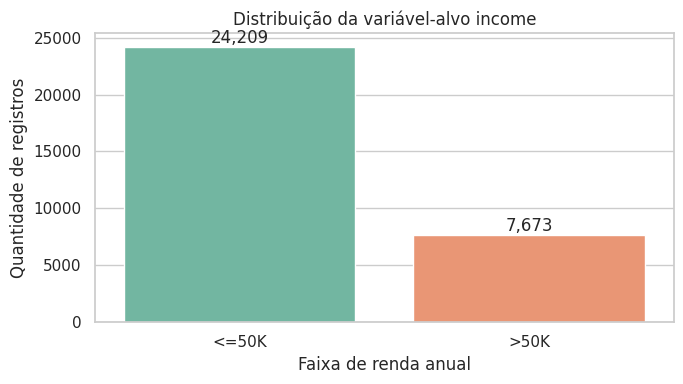

In [14]:
ordem_income = ["<=50K", ">50K"]

plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df_clean,
    x="income",
    order=ordem_income,
    hue="income",
    palette="Set2",
    legend=False
)

for barra in ax.patches:
    quantidade = int(barra.get_height())

    ax.annotate(
        f"{quantidade:,}",
        (barra.get_x() + barra.get_width() / 2, quantidade),
        ha="center",
        va="bottom"
    )

plt.title("Distribuição da variável-alvo income")
plt.xlabel("Faixa de renda anual")
plt.ylabel("Quantidade de registros")
plt.tight_layout()
plt.show()

A classe `<=50K` representa 75,93% dos registros, enquanto `>50K` representa
24,07%. Há aproximadamente 3,15 registros da classe majoritária para cada
registro da classe minoritária. Assim, um classificador ingênuo que previsse
sempre `<=50K` já obteria 75,93% de acurácia. Nas fases de modelagem, a acurácia
deverá ser analisada junto de precision, recall, F1-score e ROC-AUC.

Foi escolhida uma divisão de 80% para treino e 20% para teste: o treino permanece
grande o suficiente para análise e aprendizado, enquanto o teste fornece uma
avaliação independente. `random_state=42` garante reprodutibilidade e
`stratify=y` preserva a proporção das classes nos dois conjuntos.

In [15]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="income")
y = df_clean["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensão de X_train:", X_train.shape)
print("Dimensão de X_test:", X_test.shape)
print("Dimensão de y_train:", y_train.shape)
print("Dimensão de y_test:", y_test.shape)

Dimensão de X_train: (25505, 11)
Dimensão de X_test: (6377, 11)
Dimensão de y_train: (25505,)
Dimensão de y_test: (6377,)


In [16]:
comparacao_classes = pd.DataFrame({
    "base_completa": y.value_counts(normalize=True),
    "treino": y_train.value_counts(normalize=True),
    "teste": y_test.value_counts(normalize=True)
}).mul(100)

comparacao_classes.round(2)

,base_completa,treino,teste
income,,,
<=50K,75.93,75.93,75.93
>50K,24.07,24.07,24.07


A estratificação preservou as proporções de 75,93% e 24,07% no treino e no
teste. A partir deste ponto, a EDA detalhada utiliza apenas o conjunto de treino;
o teste permanece reservado para as fases posteriores de modelagem.

## Análise univariada

Nesta seção, cada variável será analisada individualmente. Para as variáveis
numéricas, serão avaliadas medidas de posição, dispersão, amplitude e assimetria.
A análise será realizada somente no conjunto de treino, preservando o conjunto
de teste para a avaliação futura dos modelos.

In [17]:
df_train = X_train.copy()
df_train["income"] = y_train

colunas_numericas = X_train.select_dtypes(
    include="number"
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    include="object"
).columns.tolist()

print("Variáveis numéricas:", colunas_numericas)
print("Variáveis categóricas:", colunas_categoricas)

Variáveis numéricas: ['age', 'fnlwgt', 'education_num']
Variáveis categóricas: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [18]:
estatisticas_numericas = (
    X_train[colunas_numericas]
    .describe()
    .T
)

estatisticas_numericas["mediana"] = (
    X_train[colunas_numericas].median()
)

estatisticas_numericas["assimetria"] = (
    X_train[colunas_numericas].skew()
)

estatisticas_numericas = estatisticas_numericas[
    [
        "count",
        "mean",
        "mediana",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max",
        "assimetria"
    ]
]

estatisticas_numericas.round(2)

,count,mean,mediana,std,min,25%,50%,75%,max,assimetria
age,25505.0,38.49,37.0,13.58,17.0,28.0,37.0,47.0,90.0,0.56
fnlwgt,25505.0,190264.38,178688.0,105557.13,12285.0,117849.0,178688.0,237943.0,1455435.0,1.36
education_num,25505.0,10.07,10.0,2.56,1.0,9.0,10.0,12.0,16.0,-0.31


As três variáveis numéricas não apresentaram valores ausentes no conjunto de
treino. A idade possui média de 38,49 anos e mediana de 37 anos, apresentando
assimetria positiva moderada (0,56), mas sem limites aparentemente
inconsistentes.

A variável `fnlwgt` apresentou maior dispersão e assimetria positiva (1,36),
com valores entre 12.285 e 1.455.435. Como representa o peso amostral dos
registros, seus valores elevados não foram considerados erros automaticamente.
Será avaliada uma transformação logarítmica para reduzir sua assimetria.

A variável `education_num` variou entre 1 e 16, com média de 10,07 e mediana
de 10. Sua distribuição apresentou leve assimetria negativa (-0,31). Embora
armazenada numericamente, essa variável deve ser interpretada como ordinal,
pois seus valores representam níveis ordenados de escolaridade.

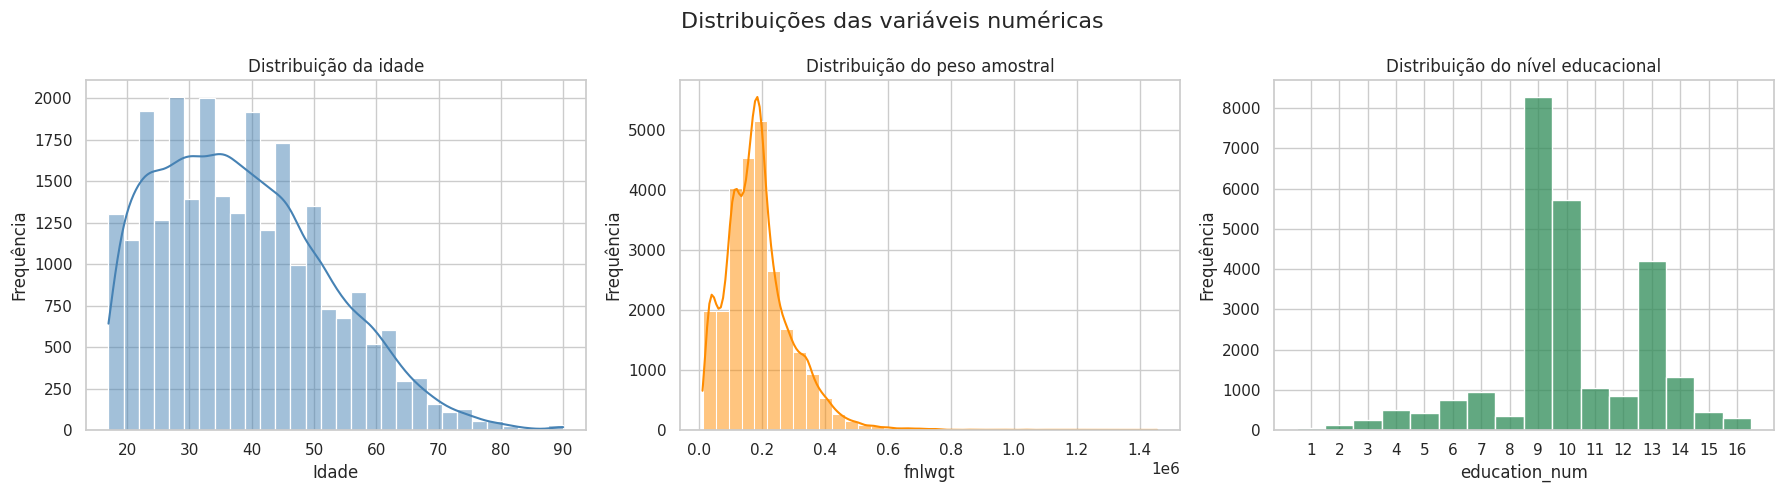

In [19]:
import numpy as np

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

sns.histplot(
    data=df_train,
    x="age",
    bins=30,
    kde=True,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Distribuição da idade")
axes[0].set_xlabel("Idade")
axes[0].set_ylabel("Frequência")


sns.histplot(
    data=df_train,
    x="fnlwgt",
    bins=35,
    kde=True,
    ax=axes[1],
    color="darkorange"
)

axes[1].set_title("Distribuição do peso amostral")
axes[1].set_xlabel("fnlwgt")
axes[1].set_ylabel("Frequência")


sns.histplot(
    data=df_train,
    x="education_num",
    bins=np.arange(0.5, 17.5, 1),
    ax=axes[2],
    color="seagreen"
)

axes[2].set_title("Distribuição do nível educacional")
axes[2].set_xlabel("education_num")
axes[2].set_ylabel("Frequência")
axes[2].set_xticks(range(1, 17))

plt.suptitle(
    "Distribuições das variáveis numéricas",
    fontsize=16
)

plt.tight_layout()
plt.show()

Os histogramas confirmaram que `age` e `fnlwgt` apresentam assimetria positiva.
A maior parte dos indivíduos está concentrada entre aproximadamente 20 e 50
anos, enquanto idades mais elevadas aparecem com frequência progressivamente
menor.

A variável `fnlwgt` apresentou uma cauda direita longa, com poucos registros
possuindo pesos amostrais muito superiores aos demais. Esses valores não foram
removidos, pois podem ser legítimos dentro do processo de ponderação censitária.
Será avaliada posteriormente uma transformação logarítmica.

Por sua vez, `education_num` apresentou concentração em níveis específicos,
especialmente 9, 10 e 13, confirmando seu caráter ordinal e discreto.

In [20]:
categoricas_selecionadas = [
    "workclass",
    "education",
    "occupation"
]

for coluna in categoricas_selecionadas:
    frequencias = (
        df_train[coluna]
        .fillna("Missing")
        .value_counts()
        .to_frame("quantidade")
    )

    frequencias["percentual"] = (
        frequencias["quantidade"] /
        len(df_train) * 100
    )

    print(f"\nDistribuição de {coluna}:")
    display(frequencias.round(2))


Distribuição de workclass:


,quantidade,percentual
workclass,,
Private,17829,69.90
Self-emp-not-inc,1967,7.71
Local-gov,1675,6.57
Missing,1395,5.47
State-gov,1016,3.98
Self-emp-inc,860,3.37
Federal-gov,747,2.93
Without-pay,10,0.04
Never-worked,6,0.02



Distribuição de education:


,quantidade,percentual
education,,
HS-grad,8275,32.44
Some-college,5713,22.40
Bachelors,4206,16.49
Masters,1314,5.15
Assoc-voc,1052,4.12
11th,932,3.65
Assoc-acdm,853,3.34
10th,741,2.91
7th-8th,496,1.94



Distribuição de occupation:


,quantidade,percentual
occupation,,
Craft-repair,3091,12.12
Prof-specialty,2950,11.57
Exec-managerial,2927,11.48
Adm-clerical,2848,11.17
Sales,2727,10.69
Missing,2584,10.13
Other-service,2520,9.88
Machine-op-inspct,1507,5.91
Transport-moving,1188,4.66


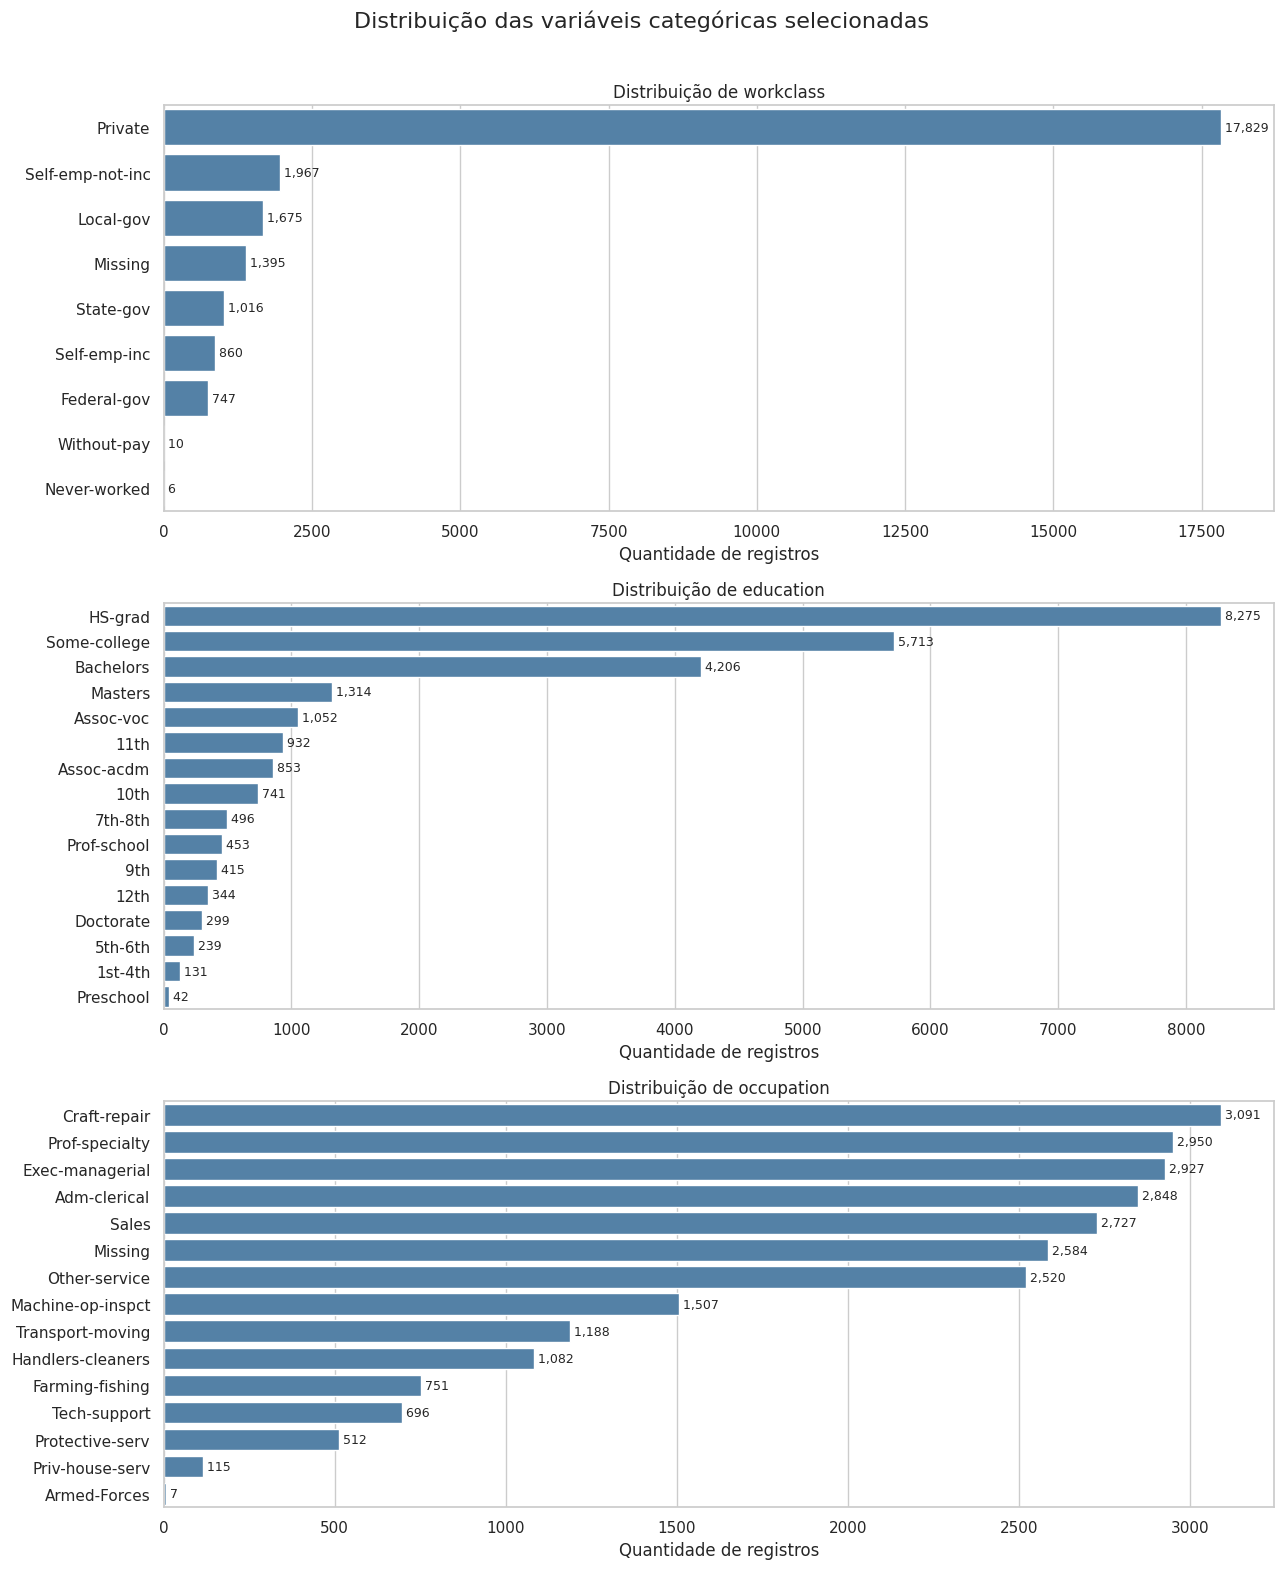

In [21]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(13, 16)
)

for ax, coluna in zip(axes, categoricas_selecionadas):

    contagens = (
        df_train[coluna]
        .fillna("Missing")
        .value_counts()
    )

    sns.barplot(
        x=contagens.values,
        y=contagens.index,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Distribuição de {coluna}")
    ax.set_xlabel("Quantidade de registros")
    ax.set_ylabel("")

    for barra in ax.patches:
        valor = int(barra.get_width())

        ax.text(
            valor,
            barra.get_y() + barra.get_height() / 2,
            f" {valor:,}",
            va="center",
            fontsize=9
        )

plt.suptitle(
    "Distribuição das variáveis categóricas selecionadas",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Entre as variáveis categóricas analisadas, `workclass` apresentou forte
concentração na categoria `Private`, correspondente a aproximadamente 70% do
conjunto de treino. A categoria `Missing` também apresentou participação
relevante, enquanto `Without-pay` e `Never-worked` foram raras.

Em `education`, os níveis `HS-grad`, `Some-college` e `Bachelors` concentraram
a maior parte dos registros, explicando os principais picos observados na
variável numérica `education_num`.

A variável `occupation` apresentou distribuição mais diversificada. Entretanto,
os valores ausentes formaram um dos maiores grupos da variável. Por esse motivo,
não será utilizada imputação pela moda, pois isso atribuiria artificialmente
uma ocupação real aos registros desconhecidos. Será criada uma categoria
explícita para representar as ausências.

In [22]:
mapa_educacao = (
    df_train[
        ["education", "education_num"]
    ]
    .drop_duplicates()
    .sort_values("education_num")
    .reset_index(drop=True)
)

mapa_educacao

print(
    "Maior quantidade de valores numéricos para uma mesma categoria:",
    mapa_educacao.groupby("education")["education_num"].nunique().max()
)

print(
    "Maior quantidade de categorias para um mesmo valor numérico:",
    mapa_educacao.groupby("education_num")["education"].nunique().max()
)

Maior quantidade de valores numéricos para uma mesma categoria: 1
Maior quantidade de categorias para um mesmo valor numérico: 1


Foi identificada uma correspondência perfeita entre `education` e
`education_num`: cada categoria textual está associada a um único valor
numérico, e cada valor numérico corresponde a uma única categoria. Portanto,
as duas variáveis representam a mesma informação.

Para evitar redundância e aumento desnecessário da dimensionalidade após o
one-hot encoding, será mantida `education_num` no pipeline inicial e removida
`education`. Essa escolha preserva a ordem dos níveis educacionais de maneira
compacta. Em etapas futuras, poderá ser comparada com a representação
categórica para verificar seu efeito no desempenho do modelo.

## Análise bivariada e multivariada

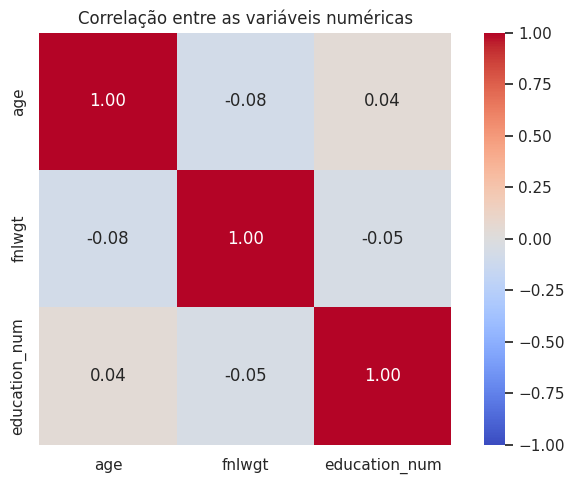

In [23]:
matriz_correlacao = (
    df_train[
        ["age", "fnlwgt", "education_num"]
    ]
    .corr()
)

matriz_correlacao.round(2)
plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlação entre as variáveis numéricas")
plt.tight_layout()
plt.show()

A matriz de correlação revelou associações lineares muito fracas entre as
variáveis numéricas. A maior correlação em valor absoluto foi observada entre
`age` e `fnlwgt` (-0,08), ainda considerada praticamente nula. Não foram
identificados indícios de multicolinearidade entre as variáveis numéricas.

Esses resultados não significam que as variáveis sejam irrelevantes para a
previsão de renda, mas apenas que não apresentam relações lineares fortes entre
si.

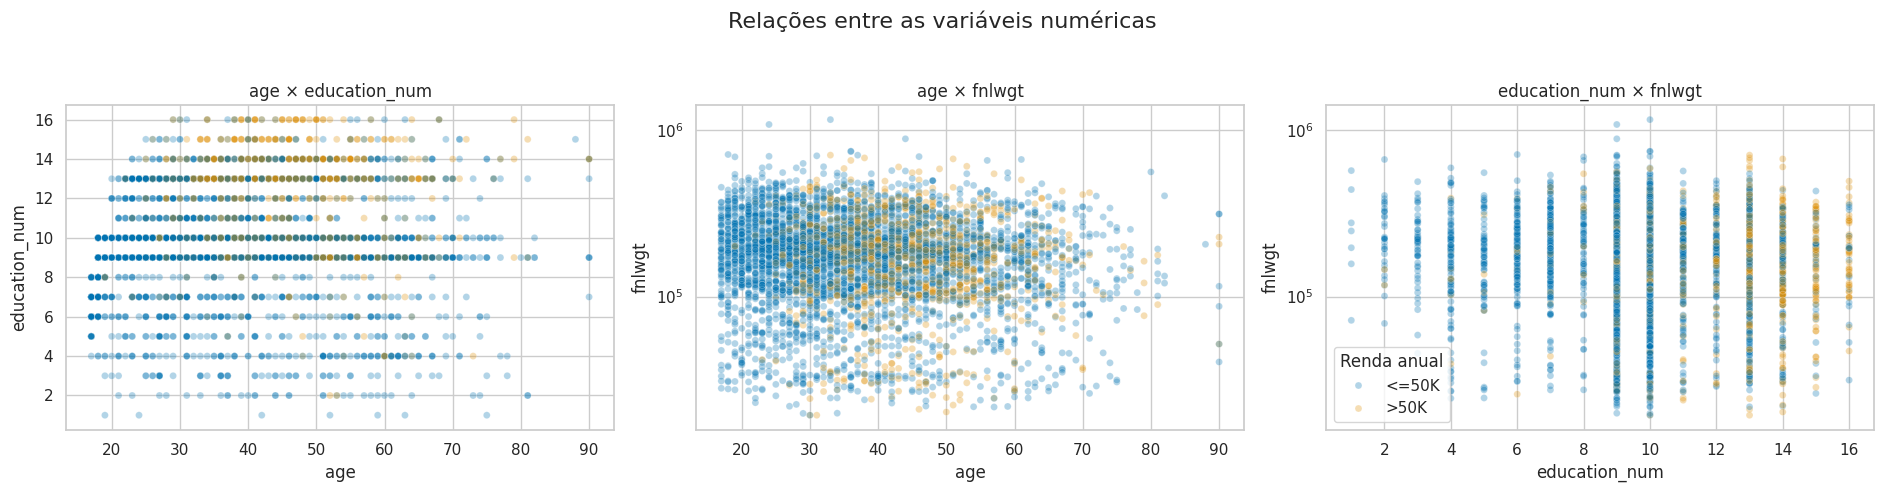

In [24]:
amostra_scatter = df_train.sample(
    n=min(5000, len(df_train)),
    random_state=42
)

pares_numericos = [
    ("age", "education_num"),
    ("age", "fnlwgt"),
    ("education_num", "fnlwgt")
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5)
)

for ax, (x, y) in zip(axes, pares_numericos):

    sns.scatterplot(
        data=amostra_scatter,
        x=x,
        y=y,
        hue="income",
        hue_order=["<=50K", ">50K"],
        alpha=0.30,
        s=25,
        ax=ax
    )

    ax.set_title(f"{x} × {y}")

    if y == "fnlwgt":
        ax.set_yscale("log")

for ax in axes[:-1]:
    ax.get_legend().remove()

axes[-1].legend(title="Renda anual")

plt.suptitle(
    "Relações entre as variáveis numéricas",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [25]:
analise_faixa_idade = df_train.copy()

analise_faixa_idade["faixa_idade"] = pd.cut(
    analise_faixa_idade["age"],
    bins=[16, 29, 39, 49, 59, 100],
    labels=[
        "17–29",
        "30–39",
        "40–49",
        "50–59",
        "60+"
    ]
)

analise_faixa_idade["income_alta"] = (
    analise_faixa_idade["income"] == ">50K"
).astype(int)

resumo_por_idade = (
    analise_faixa_idade
    .groupby("faixa_idade", observed=True)
    .agg(
        quantidade=("age", "size"),
        media_fnlwgt=("fnlwgt", "mean"),
        mediana_fnlwgt=("fnlwgt", "median"),
        media_education=("education_num", "mean"),
        taxa_income_alta=("income_alta", "mean")
    )
)

resumo_por_idade["taxa_income_alta"] *= 100

resumo_por_idade.round(2)

,quantidade,media_fnlwgt,mediana_fnlwgt,media_education,taxa_income_alta
faixa_idade,,,,,
17–29,7652,199079.85,188123.5,9.69,5.23
30–39,6775,194622.32,181716.0,10.30,27.14
40–49,5630,186067.16,175935.0,10.54,36.98
50–59,3431,179123.72,170050.0,10.01,38.36
60+,2017,172848.92,165479.0,9.52,24.84


A análise por faixas etárias mostrou que a maior concentração de registros
ocorre entre 17 e 29 anos. Apesar da impressão inicial obtida no scatter plot,
o peso amostral médio diminuiu progressivamente com a idade, indicando que a
densidade visual de pontos não representava maior ponderação.

A taxa de renda superior a US$ 50 mil apresentou comportamento não linear:
cresceu de 5,23% entre 17 e 29 anos para 38,36% entre 50 e 59 anos, diminuindo
para 24,84% entre pessoas com 60 anos ou mais. Esse resultado sugere que a idade
possui relação relevante com o target, mas que essa associação não é
adequadamente representada por uma tendência linear simples.

## Análise de variáveis categóricas × target

,education,quantidade,casos_income_alta,taxa_income_alta
13,Preschool,42,0,0.00
4,5th-6th,239,8,3.35
3,1st-4th,131,5,3.82
6,9th,415,20,4.82
1,11th,932,49,5.26
5,7th-8th,496,28,5.65
2,12th,344,24,6.98
0,10th,741,52,7.02
11,HS-grad,8275,1332,16.10
15,Some-college,5713,1085,18.99


,sex,quantidade,casos_income_alta,taxa_income_alta
0,Female,8468,920,10.86
1,Male,17037,5218,30.63


,race,quantidade,casos_income_alta,taxa_income_alta
3,Other,208,18,8.65
2,Black,2458,303,12.33
0,Amer-Indian-Eskimo,244,32,13.11
4,White,21855,5586,25.56
1,Asian-Pac-Islander,740,199,26.89


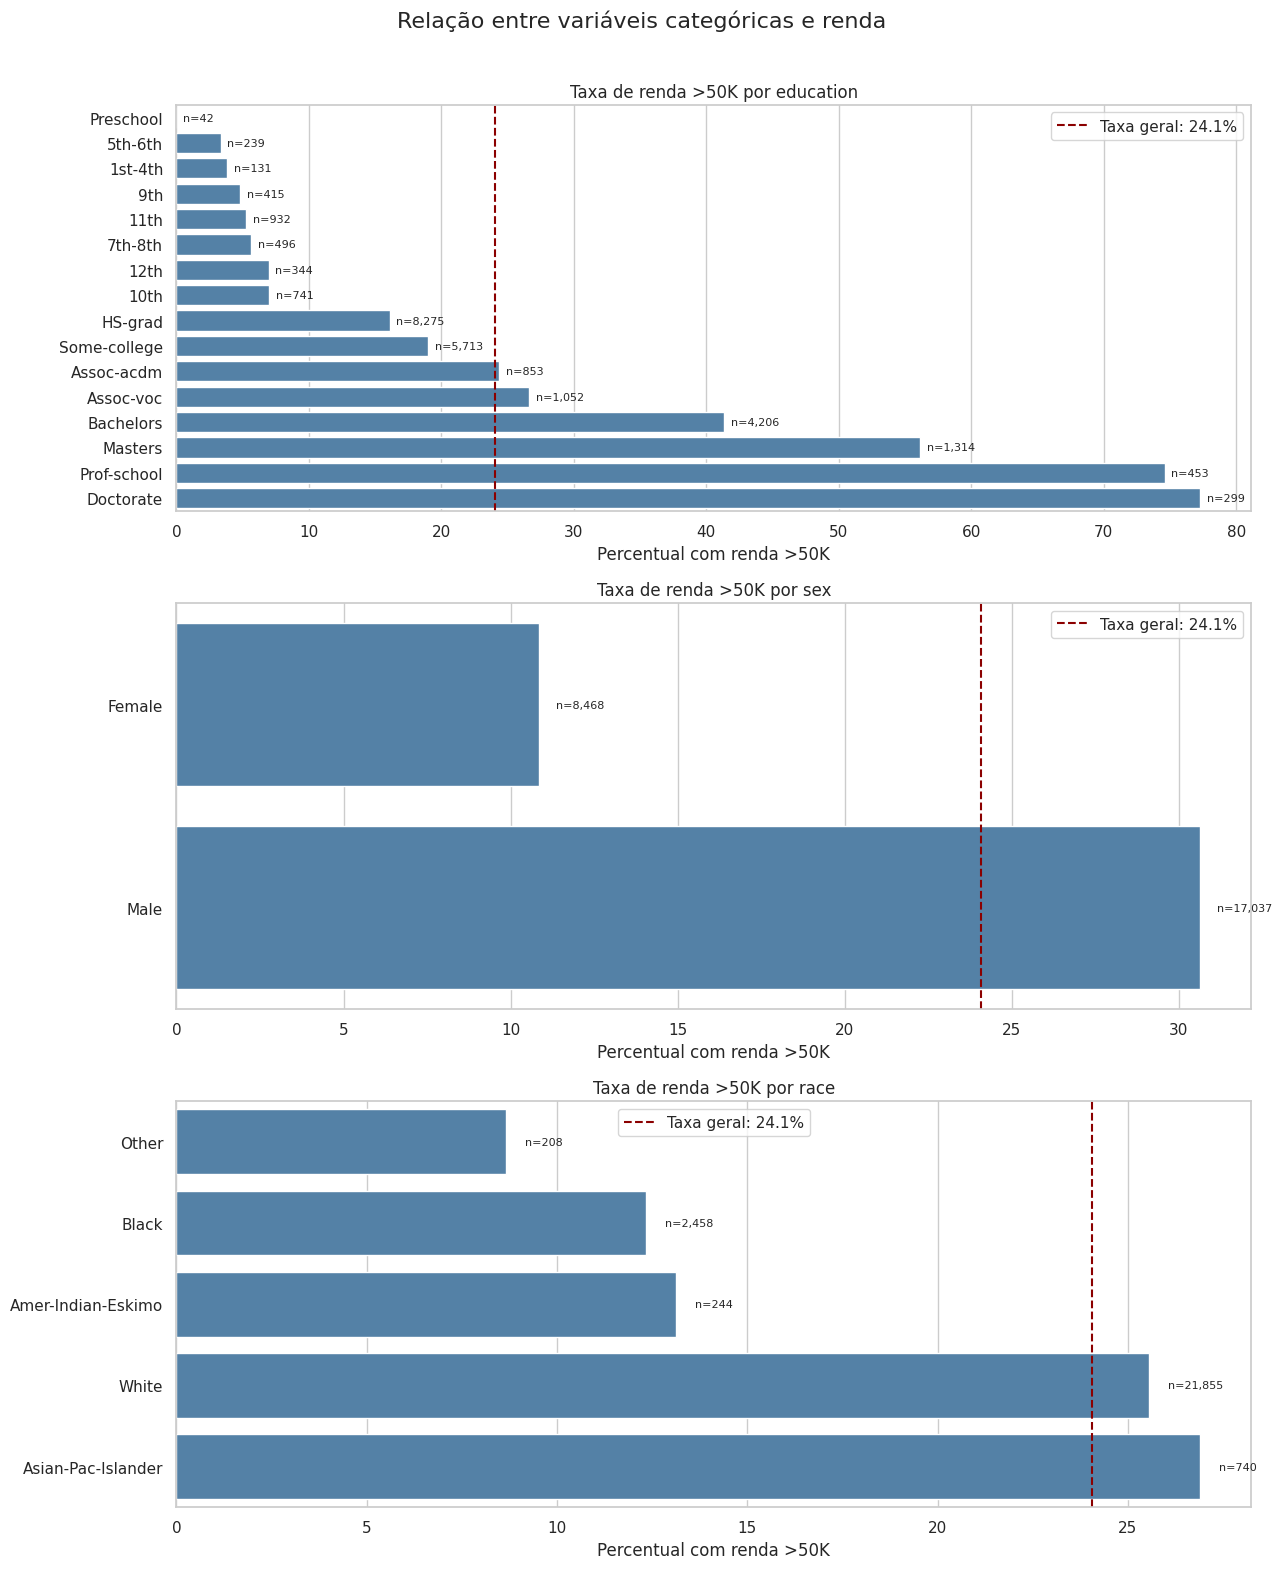

In [26]:
categoricas_target = [
    "education",
    "sex",
    "race"
]

taxa_geral = (
    df_train["income"] == ">50K"
).mean() * 100

fig, axes = plt.subplots(
    3,
    1,
    figsize=(13, 16)
)

for ax, coluna in zip(axes, categoricas_target):

    tabela = (
        df_train
        .assign(income_alta=df_train["income"] == ">50K")
        .groupby(coluna, observed=True)
        .agg(
            quantidade=("income", "size"),
            casos_income_alta=("income_alta", "sum"),
            taxa_income_alta=("income_alta", "mean")
        )
        .reset_index()
    )

    tabela["taxa_income_alta"] *= 100
    tabela = tabela.sort_values("taxa_income_alta")

    display(tabela.round(2))

    sns.barplot(
        data=tabela,
        x="taxa_income_alta",
        y=coluna,
        order=tabela[coluna],
        ax=ax,
        color="steelblue"
    )

    ax.axvline(
        taxa_geral,
        color="darkred",
        linestyle="--",
        label=f"Taxa geral: {taxa_geral:.1f}%"
    )

    ax.set_title(f"Taxa de renda >50K por {coluna}")
    ax.set_xlabel("Percentual com renda >50K")
    ax.set_ylabel("")
    ax.legend()

    for barra, quantidade in zip(
        ax.patches,
        tabela["quantidade"]
    ):
        ax.text(
            barra.get_width() + 0.5,
            barra.get_y() + barra.get_height() / 2,
            f"n={quantidade:,}",
            va="center",
            fontsize=8
        )

plt.suptitle(
    "Relação entre variáveis categóricas e renda",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

A escolaridade apresentou forte associação com a renda. A proporção de
indivíduos com renda superior a US$ 50 mil aumentou de 16,10% entre pessoas com
`HS-grad` para 41,37% entre bacharéis, 56,16% entre mestres e 77,26% entre
doutores. Esse comportamento indica uma associação positiva acentuada, mas não
permite concluir causalidade.

Também foi observada diferença relevante entre os sexos registrados. A taxa de
renda superior a US$ 50 mil foi de 30,63% entre homens e 10,86% entre mulheres.
Além disso, os homens constituem aproximadamente 66,80% do conjunto de treino,
indicando simultaneamente diferença na composição da amostra e na taxa de renda
alta dentro de cada grupo.

Entre as categorias raciais, `Asian-Pac-Islander` e `White` apresentaram taxas
de 26,89% e 25,56%, respectivamente, ambas acima da taxa geral de 24,07%. Esses
resultados devem ser interpretados considerando as grandes diferenças nos
tamanhos dos grupos e não estabelecem uma relação causal ou intrínseca entre
raça e renda. As associações podem refletir desigualdades históricas,
socioeconômicas e outras variáveis não observadas.

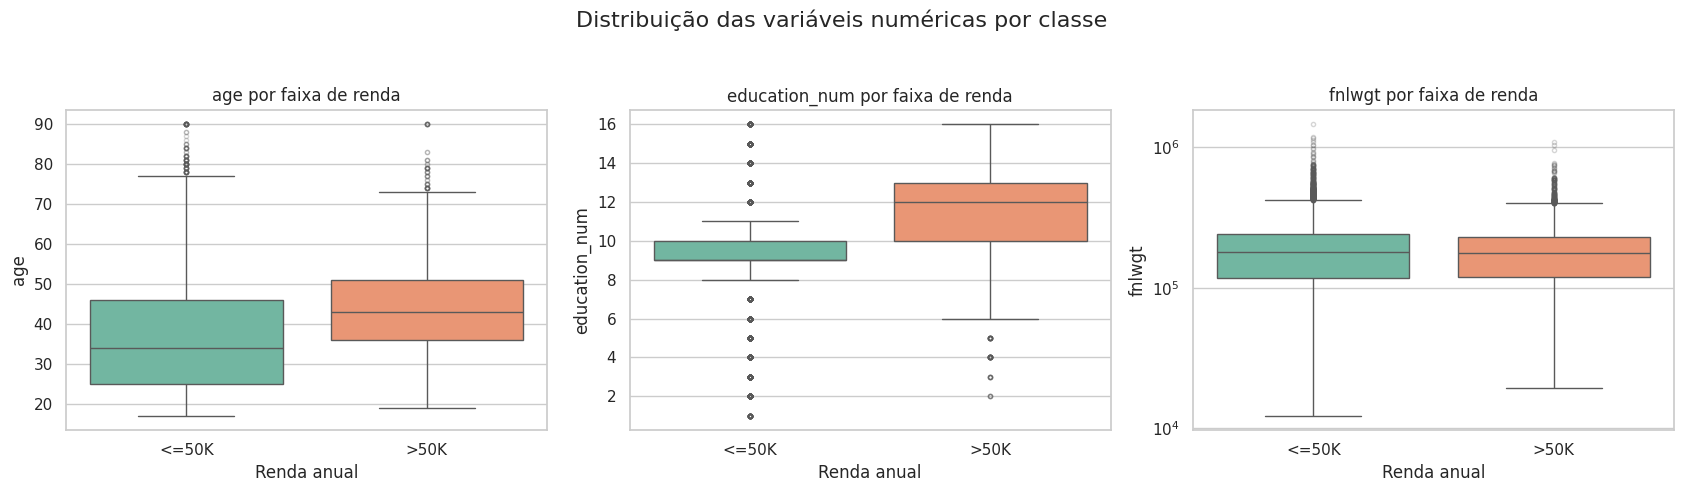

In [27]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

variaveis_boxplot = [
    "age",
    "education_num",
    "fnlwgt"
]

for ax, coluna in zip(axes, variaveis_boxplot):

    sns.boxplot(
        data=df_train,
        x="income",
        y=coluna,
        order=["<=50K", ">50K"],
        hue="income",
        palette="Set2",
        legend=False,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.25
        },
        ax=ax
    )

    ax.set_title(f"{coluna} por faixa de renda")
    ax.set_xlabel("Renda anual")
    ax.set_ylabel(coluna)

axes[2].set_yscale("log")

plt.suptitle(
    "Distribuição das variáveis numéricas por classe",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Os boxplots evidenciaram diferenças entre as classes de renda. A classe `>50K`
apresentou idade mediana superior à classe `<=50K`, embora tenha sido observada
considerável sobreposição entre as distribuições.

A diferença foi mais acentuada em `education_num`: indivíduos da classe de renda
alta apresentaram níveis educacionais centrais superiores. Os valores extremos
de escolaridade foram mantidos, pois correspondem a categorias válidas e podem
representar exceções importantes ao padrão geral.

As distribuições de `fnlwgt` foram semelhantes entre as duas classes, sugerindo
baixo poder de separação quando utilizado diretamente como feature.

In [28]:
resumo_outliers = []

for coluna in colunas_numericas:

    q1 = X_train[coluna].quantile(0.25)
    q3 = X_train[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara_outlier = (
        (X_train[coluna] < limite_inferior) |
        (X_train[coluna] > limite_superior)
    )

    resumo_outliers.append({
        "variavel": coluna,
        "q1": q1,
        "q3": q3,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "quantidade_outliers": mascara_outlier.sum(),
        "percentual_outliers": mascara_outlier.mean() * 100
    })

resumo_outliers = pd.DataFrame(
    resumo_outliers
).set_index("variavel")

resumo_outliers.round(2)

,q1,q3,limite_inferior,limite_superior,quantidade_outliers,percentual_outliers
variavel,,,,,,
age,28.0,47.0,-0.5,75.5,179,0.70
fnlwgt,117849.0,237943.0,-62292.0,418084.0,775,3.04
education_num,9.0,12.0,4.5,16.5,908,3.56


O método IQR identificou 0,70% dos valores de `age`, 3,04% de `fnlwgt` e
3,56% de `education_num` como outliers. Entretanto, a análise conceitual
indicou que esses valores não devem ser removidos automaticamente.

Em `age`, foram sinalizadas pessoas com mais de 75,5 anos, que representam
idades raras, porém plausíveis. Em `education_num`, o método classificou os
níveis educacionais de 1 a 4 como extremos, embora sejam categorias válidas.
Os valores elevados de `fnlwgt` também podem ser legítimos, pois essa variável
representa o peso amostral calculado pelo censo.

Assim, optou-se por manter todas as observações. Para `fnlwgt`, será avaliada
uma transformação `log1p` com o objetivo de reduzir sua assimetria sem excluir
registros.

In [29]:
import numpy as np

fnlwgt_log = np.log1p(X_train["fnlwgt"])

comparacao_assimetria = pd.DataFrame({
    "representacao": [
        "fnlwgt original",
        "log1p(fnlwgt)"
    ],
    "assimetria": [
        X_train["fnlwgt"].skew(),
        fnlwgt_log.skew()
    ],
    "media": [
        X_train["fnlwgt"].mean(),
        fnlwgt_log.mean()
    ],
    "desvio_padrao": [
        X_train["fnlwgt"].std(),
        fnlwgt_log.std()
    ]
})

comparacao_assimetria.round(3)

,representacao,assimetria,media,desvio_padrao
0,fnlwgt original,1.362,190264.384,105557.133
1,log1p(fnlwgt),-0.842,11.986,0.631


A transformação `log1p` reduziu a assimetria de `fnlwgt` de 1,362 para -0,842.
Em valor absoluto, houve redução aproximada de 38%. A transformação não tornou a
distribuição perfeitamente simétrica, mas comprimiu a cauda direita sem remover
observações. Por isso, ela será aplicada quando `fnlwgt` entrar como feature e
no PCA. Se `fnlwgt` for usado futuramente como peso amostral, seus valores
originais deverão ser preservados para essa finalidade.

## Preparação das variáveis numéricas para o PCA

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler

numericas_regulares = [
    "age",
    "education_num"
]

numericas_assimetricas = [
    "fnlwgt"
]

pipeline_numericas_regulares = Pipeline([
    (
        "imputacao",
        SimpleImputer(strategy="median")
    ),
    (
        "padronizacao",
        StandardScaler()
    )
])

pipeline_fnlwgt = Pipeline([
    (
        "imputacao",
        SimpleImputer(strategy="median")
    ),
    (
        "logaritmo",
        FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )
    ),
    (
        "padronizacao",
        StandardScaler()
    )
])

preprocessador_pca = ColumnTransformer([
    (
        "numericas_regulares",
        pipeline_numericas_regulares,
        numericas_regulares
    ),
    (
        "fnlwgt",
        pipeline_fnlwgt,
        numericas_assimetricas
    )
])

X_train_numerico = preprocessador_pca.fit_transform(
    X_train
)

print("Dimensão antes:", X_train[numericas_regulares + numericas_assimetricas].shape)
print("Dimensão depois:", X_train_numerico.shape)

print("\nMédias após padronização:")
print(X_train_numerico.mean(axis=0).round(4))

print("\nDesvios-padrão após padronização:")
print(X_train_numerico.std(axis=0).round(4))

Dimensão antes: (25505, 3)
Dimensão depois: (25505, 3)

Médias após padronização:
[0. 0. 0.]

Desvios-padrão após padronização:
[1. 1. 1.]


## Redução de dimensionalidade com PCA

In [31]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=42
)

X_train_pca = pca.fit_transform(
    X_train_numerico
)

print("Dimensão antes do PCA:", X_train_numerico.shape)
print("Dimensão depois do PCA:", X_train_pca.shape)

Dimensão antes do PCA: (25505, 3)
Dimensão depois do PCA: (25505, 2)


In [32]:
variancia_pca = pd.DataFrame({
    "componente": ["PC1", "PC2"],
    "variancia_explicada": pca.explained_variance_ratio_,
    "variancia_acumulada": np.cumsum(
        pca.explained_variance_ratio_
    )
})

variancia_pca["variancia_explicada"] *= 100
variancia_pca["variancia_acumulada"] *= 100

variancia_pca.round(2)

,componente,variancia_explicada,variancia_acumulada
0,PC1,36.53,36.53
1,PC2,32.22,68.75


In [33]:
nomes_numericas_pca = [
    "age",
    "education_num",
    "log1p_fnlwgt"
]

cargas_pca = pd.DataFrame(
    pca.components_.T,
    index=nomes_numericas_pca,
    columns=["PC1", "PC2"]
)

cargas_pca.round(3)

,PC1,PC2
age,0.610,-0.353
education_num,0.508,0.861
log1p_fnlwgt,-0.608,0.366


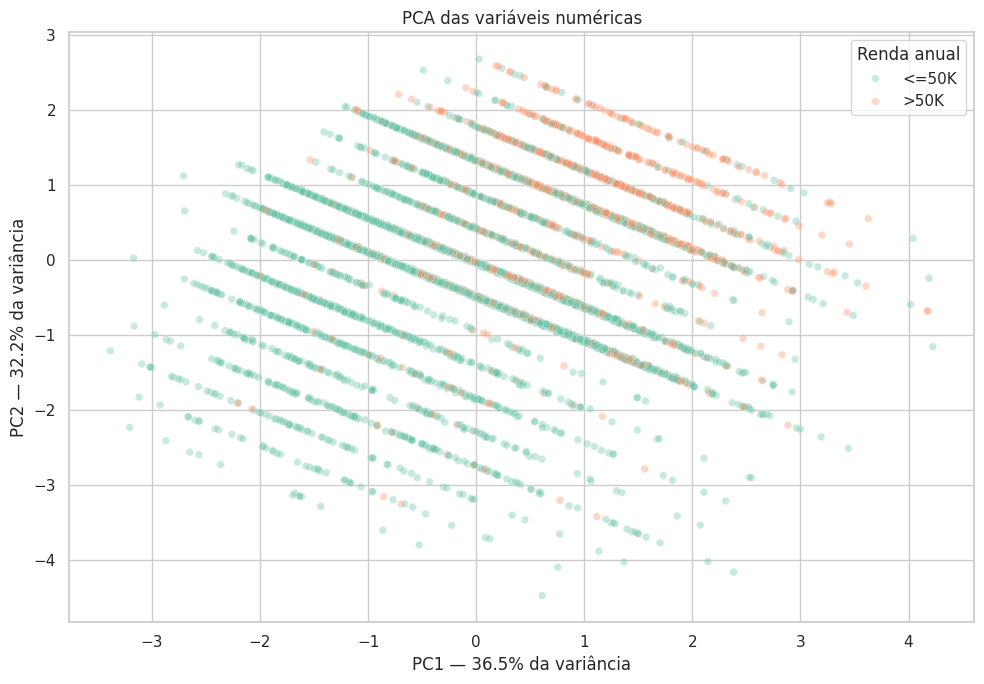

In [34]:
df_pca = pd.DataFrame(
    X_train_pca,
    columns=["PC1", "PC2"]
)

# to_numpy evita problemas de alinhamento entre índices
df_pca["income"] = y_train.to_numpy()

amostra_pca = df_pca.sample(
    n=min(8000, len(df_pca)),
    random_state=42
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=amostra_pca,
    x="PC1",
    y="PC2",
    hue="income",
    hue_order=["<=50K", ">50K"],
    alpha=0.35,
    s=30,
    palette="Set2"
)

plt.title("PCA das variáveis numéricas")
plt.xlabel(
    f"PC1 — {pca.explained_variance_ratio_[0]:.1%} da variância"
)
plt.ylabel(
    f"PC2 — {pca.explained_variance_ratio_[1]:.1%} da variância"
)
plt.legend(title="Renda anual")
plt.tight_layout()
plt.show()

As duas primeiras componentes principais explicaram conjuntamente 68,7% da
variância das três features numéricas. A projeção apresentou faixas paralelas
associadas ao caráter discreto de `education_num`.

Embora tenha sido observada maior concentração da classe `>50K` em uma região
do plano, houve ampla sobreposição entre as classes. Portanto, as variáveis
numéricas apresentam algum poder de separação, mas não são suficientes para
distinguir completamente as faixas de renda. Variáveis categóricas deverão ser
incorporadas durante a modelagem.

In [35]:
contribuicoes_pca = (
    cargas_pca
    .pow(2)
    .mul(100)
)

contribuicoes_pca.round(1)

,PC1,PC2
age,37.2,12.4
education_num,25.8,74.1
log1p_fnlwgt,37.0,13.4


A primeira componente principal explicou 36,5% da variância e foi formada
principalmente por `age` e `log1p(fnlwgt)`, com contribuições de 37,2% e 37,0%.
Essas variáveis apresentaram direções opostas no componente, enquanto
`education_num` contribuiu com 25,8%.

A segunda componente explicou 32,2% da variância e foi dominada por
`education_num`, responsável por 74,1% de sua composição. Portanto, a posição
vertical dos registros no gráfico está relacionada principalmente ao nível
educacional.

As duas componentes preservaram 68,7% da variabilidade numérica. Apesar de
alguma concentração da classe `>50K` em regiões associadas a maior
escolaridade, houve ampla sobreposição entre as classes.

## Pipeline completo de pré-processamento

### Estratégias escolhidas

| Desafio | Estratégia | Justificativa |
|---|---|---|
| Ausências categóricas | Categoria constante `Missing` | Preserva o possível sinal da ausência e não inventa a classe modal |
| Ausências numéricas | Mediana no pipeline | Salvaguarda robusta a extremos para novos dados |
| Outliers plausíveis | Manutenção das linhas | Idades e níveis educacionais são válidos; `fnlwgt` é um peso amostral |
| Assimetria de `fnlwgt` | `log1p` | Reduziu o valor absoluto da assimetria sem excluir registros |
| Categóricas nominais | One-hot encoding | Evita impor ordem artificial às categorias |
| Escalas numéricas | `StandardScaler` | Necessário para PCA e métodos sensíveis à escala |
| Redundância educacional | Descartar `education` no pipeline | Correspondência perfeita com `education_num` |
| Classe desbalanceada | Split estratificado e métricas por classe | Acurácia isolada pode ser enganosa |

In [36]:
from sklearn.preprocessing import OneHotEncoder

# 'education' não entra na lista porque duplica exatamente 'education_num'.
categoricas_modelo = [
    "workclass",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native_country"
]

pipeline_categoricas = Pipeline([
    (
        "imputacao",
        SimpleImputer(strategy="constant", fill_value="Missing")
    ),
    (
        "one_hot",
        OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    )
])

In [37]:
preprocessador_final = ColumnTransformer(
    transformers=[
        (
            "numericas_regulares",
            pipeline_numericas_regulares,
            ["age", "education_num"]
        ),
        (
            "fnlwgt",
            pipeline_fnlwgt,
            ["fnlwgt"]
        ),
        (
            "categoricas",
            pipeline_categoricas,
            categoricas_modelo
        )
    ],
    remainder="drop"
)
pipeline_preprocessamento = Pipeline([
    (
        "preprocessamento",
        preprocessador_final
    )
])

X_train_preparado = (
    pipeline_preprocessamento
    .fit_transform(X_train)
)

X_test_preparado = (
    pipeline_preprocessamento
    .transform(X_test)
)

print("Treino original:", X_train.shape)
print("Treino transformado:", X_train_preparado.shape)

print("Teste original:", X_test.shape)
print("Teste transformado:", X_test_preparado.shape)

Treino original: (25505, 11)
Treino transformado: (25505, 89)
Teste original: (6377, 11)
Teste transformado: (6377, 89)


In [38]:
from scipy.sparse import issparse

valores_treino = (
    X_train_preparado.data
    if issparse(X_train_preparado)
    else X_train_preparado
)

print(
    "Valores NaN após o pipeline:",
    np.isnan(valores_treino).sum()
)

nomes_features_finais = (
    pipeline_preprocessamento
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)

print(
    "Quantidade de features finais:",
    len(nomes_features_finais)
)

print(
    "Primeiras features:",
    nomes_features_finais[:20]
)

Valores NaN após o pipeline: 0
Quantidade de features finais: 89
Primeiras features: ['numericas_regulares__age' 'numericas_regulares__education_num'
 'fnlwgt__fnlwgt' 'categoricas__workclass_Federal-gov'
 'categoricas__workclass_Local-gov' 'categoricas__workclass_Missing'
 'categoricas__workclass_Never-worked' 'categoricas__workclass_Private'
 'categoricas__workclass_Self-emp-inc'
 'categoricas__workclass_Self-emp-not-inc'
 'categoricas__workclass_State-gov' 'categoricas__workclass_Without-pay'
 'categoricas__marital_status_Divorced'
 'categoricas__marital_status_Married-AF-spouse'
 'categoricas__marital_status_Married-civ-spouse'
 'categoricas__marital_status_Married-spouse-absent'
 'categoricas__marital_status_Never-married'
 'categoricas__marital_status_Separated'
 'categoricas__marital_status_Widowed'
 'categoricas__occupation_Adm-clerical']


### Variante do pipeline com PCA nas variáveis numéricas

O pipeline base preserva as três numéricas porque o PCA perdeu 31,25% da
variabilidade e não separou completamente as classes. Para atender também à
possibilidade de incorporar a redução dimensional à modelagem, construímos uma
segunda variante. Nela, somente o bloco numérico é reduzido de três para duas
componentes; as categóricas continuam passando por imputação e one-hot.

In [39]:
# Pipeline numérico completo: preparação seguida de PCA.
pipeline_numerico_com_pca = Pipeline([
    (
        "preparacao_numerica",
        ColumnTransformer(
            transformers=[
                (
                    "regulares",
                    pipeline_numericas_regulares,
                    ["age", "education_num"]
                ),
                (
                    "fnlwgt",
                    pipeline_fnlwgt,
                    ["fnlwgt"]
                )
            ],
            remainder="drop"
        )
    ),
    (
        "pca",
        PCA(n_components=2, random_state=42)
    )
])

preprocessador_final_com_pca = ColumnTransformer(
    transformers=[
        (
            "numericas_pca",
            pipeline_numerico_com_pca,
            ["age", "education_num", "fnlwgt"]
        ),
        (
            "categoricas",
            pipeline_categoricas,
            categoricas_modelo
        )
    ],
    remainder="drop"
)

pipeline_preprocessamento_com_pca = Pipeline([
    ("preprocessamento", preprocessador_final_com_pca)
])

X_train_preparado_com_pca = (
    pipeline_preprocessamento_com_pca.fit_transform(X_train)
)
X_test_preparado_com_pca = (
    pipeline_preprocessamento_com_pca.transform(X_test)
)

print("Treino com PCA:", X_train_preparado_com_pca.shape)
print("Teste com PCA:", X_test_preparado_com_pca.shape)

assert X_train_preparado_com_pca.shape[1] == X_test_preparado_com_pca.shape[1]
print("✓ Pipeline com PCA produz estrutura consistente em treino e teste.")

Treino com PCA: (25505, 88)
Teste com PCA: (6377, 88)
✓ Pipeline com PCA produz estrutura consistente em treino e teste.


O pipeline base foi construído com `Pipeline` e `ColumnTransformer`. As
variáveis `age` e `education_num` recebem imputação pela mediana e
padronização. A mediana foi escolhida por ser resistente a valores extremos,
embora as numéricas atuais não apresentem ausências. Ela funciona como uma
salvaguarda para novos dados.

A variável `fnlwgt` recebe imputação pela mediana, transformação `log1p` e
padronização. O logaritmo reduziu o valor absoluto da assimetria de 1,362 para
0,842, preservando todas as observações.

As categóricas recebem a categoria explícita `Missing` e one-hot encoding.
One-hot foi escolhido porque as categorias são nominais; label encoding criaria
uma ordem numérica artificial entre, por exemplo, profissões e países. O
parâmetro `handle_unknown="ignore"` permite transformar categorias futuras sem
interromper o pipeline.

O `StandardScaler` coloca as numéricas em média zero e desvio-padrão um. Isso
evita que `fnlwgt`, medido em centenas de milhares, domine métodos sensíveis à
escala. A variável `education` é descartada automaticamente pelo
`ColumnTransformer`, por não ser atribuída a nenhum transformador e por possuir
correspondência perfeita com `education_num`.

O pipeline base preserva as três numéricas e gera 89 features. A variante com
PCA, apresentada abaixo, reduz apenas o bloco numérico de três para duas
componentes e deve ser comparada ao pipeline base durante a modelagem.

## Relatório executivo

### Estrutura e qualidade

A versão analisada da base Adult Income Census possuía 31.947 registros, 11
features preditoras e o target binário `income`. Após a remoção de 65 duplicatas
exatas (0,20%), restaram 31.882 registros. A base foi dividida de forma
estratificada em 25.505 observações de treino e 6.377 de teste.

Ausências originalmente registradas como `?` foram encontradas em `workclass`,
`occupation` e `native_country`. A coluna `occupation` também continha o valor
inválido `occupation`. Esses marcadores foram convertidos em `NaN` e serão
representados pela categoria explícita `Missing` dentro do pipeline.

### Principais achados

A classe `<=50K` correspondeu a 75,93% da base, contra 24,07% para `>50K`,
estabelecendo um baseline ingênuo de 75,93% de acurácia. A idade apresentou
relação não linear com o target: a taxa de renda alta cresceu de 5,23% na faixa
de 17–29 anos para 38,36% entre 50–59 anos, caindo para 24,84% entre pessoas com
60 anos ou mais.

Escolaridade foi a variável com associação descritiva mais clara. A taxa de
`>50K` passou de 16,10% em `HS-grad` para 41,37% em `Bachelors`, 56,16% em
`Masters` e 77,26% em `Doctorate`. `education` e `education_num` apresentaram
correspondência perfeita; por isso, somente `education_num` entra no pipeline.

A matriz de correlação mostrou associações lineares muito fracas entre as
numéricas. `fnlwgt` apresentou distribuições semelhantes nas duas classes,
sugerindo baixo poder de separação quando usado diretamente como feature. Como
se trata de peso amostral, fases posteriores deverão comparar seu uso como
feature, sua exclusão e seu emprego como `sample_weight`.

Foram observadas diferenças nas taxas de renda por sexo e raça. A taxa de
`>50K` foi de 30,63% entre homens e 10,86% entre mulheres. As categorias
`Asian-Pac-Islander` e `White` apresentaram 26,89% e 25,56%, respectivamente.
Essas associações não são causais ou intrínsecas e podem refletir desigualdades
históricas, composição da amostra e variáveis omitidas.

### Outliers, transformação e PCA

O IQR sinalizou 0,70% dos valores de `age`, 3,04% de `fnlwgt` e 3,56% de
`education_num`. Os casos foram mantidos porque correspondem a idades plausíveis,
níveis educacionais válidos e pesos amostrais potencialmente legítimos. `fnlwgt`
recebeu `log1p`, reduzindo o valor absoluto de sua assimetria em aproximadamente
38%.

As duas primeiras componentes do PCA explicaram 68,75% da variância numérica.
PC1 foi formada principalmente por `age` e `log1p(fnlwgt)`, enquanto PC2 foi
dominada por `education_num`, com contribuição de 74,1%. A visualização mostrou
ampla sobreposição entre as classes; portanto, o PCA não demonstrou separação
suficiente usando apenas as numéricas.

### Estratégias propostas para modelagem

O pipeline aplica mediana às numéricas, categoria `Missing` às categóricas,
`log1p` em `fnlwgt`, `StandardScaler` e one-hot encoding. Foram construídas duas
variantes: uma que preserva as três numéricas e outra que reduz esse bloco a duas
componentes com PCA. Nas próximas fases, elas deverão ser comparadas com
validação cruzada estratificada.

Devido ao desbalanceamento, a avaliação deverá incluir precision, recall,
F1-score, ROC-AUC e matriz de confusão. Também devem ser comparados modelos com e
sem `fnlwgt`, sexo e raça, acompanhados por métricas desagregadas entre grupos.